> Runs on its own: all the code is inside this notebook (copied from `src/`), so you can open just this file, e.g. in Colab, or run it from the cloned repo (Anaconda Jupyter on Windows/Linux/macOS, or Colab after cloning https://github.com/Rishabh-bgp/wuweidl-daoist-gated-wind-forecasting). Install dependencies once with `%pip install -r requirements.txt` (or `%pip install -r ../requirements.txt` from `notebooks/`). The data cell finds the committed synthetic CSV, downloads it from GitHub, or regenerates it.

# Walkthrough: WuWeiDL (Wu Wei gate + Feng-Qi encoder)
Simplified version of `src/train_eval.py` (no ablations). Reference implementation of my paper, rebuilt on synthetic data; numbers will differ from the published ones.

## Please read first: what these numbers mean
This notebook is a **short teaching demo on synthetic (computer-generated) data**. It is **not** a reproduction of the paper's results, and the numbers below should not be compared with the paper's tables.

- The data in `data/` is made up by a seeded generator. The real SCADA data is confidential and is not in this repository.
- The model trains for only a few minutes on a CPU, so it is much smaller and less tuned than in the paper.
- The model predicts the **change from the last reading** (the *persistence* forecast, "next hour = this hour") and adds it back. A fair test of any wind forecaster is whether it beats persistence, so both are printed side by side, with the real numbers, whatever they are.

In [1]:
# install anything missing (Colab already has most of these)
import importlib.util, subprocess, sys
missing = [m for m in ['numpy','pandas','torch','matplotlib'] if importlib.util.find_spec(m) is None]
if missing: subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q'] + [{'sklearn': 'scikit-learn'}.get(m, m) for m in missing])
import os, urllib.request
from pathlib import Path
os.environ.setdefault('OMP_NUM_THREADS', '2')
REPO = 'wuweidl-daoist-gated-wind-forecasting'

def find_csv(name):
    """../data/synthetic -> data/synthetic -> GitHub raw URL -> regenerate with the seeded generator."""
    for p in [Path.cwd().parent / 'data' / 'synthetic' / name, Path.cwd() / 'data' / 'synthetic' / name]:
        if p.exists(): return p
    out = Path.cwd() / 'data' / 'synthetic' / name; out.parent.mkdir(parents=True, exist_ok=True)
    try:
        urllib.request.urlretrieve(f'https://raw.githubusercontent.com/Rishabh-bgp/{REPO}/main/data/synthetic/{name}', out); return out
    except Exception as e:
        print('download failed, regenerating synthetic data:', e)
    if name == 'synthetic_sites.csv':
        synthetic_sites(n_hours=24 * 60, seed=0).to_csv(out, index=False)
    else:
        d = synthetic_scada(24 * 120, seed=0); d.index.name = 'timestamp'; d.to_csv(out)
    return out

import numpy as np, torch, matplotlib.pyplot as plt
torch.manual_seed(0); torch.set_num_threads(2)
EPOCHS = 10   # short CPU demo (the full script in src/ trains longer)
print('ready')

ready


## 0. The method's code
This cell holds the model, data and metric code, copied from `src/` so the notebook needs nothing else. You can skip reading it; the steps below use it.

In [2]:
# ===== from src/data.py =====
import numpy as np
import pandas as pd

ALIASES = {
    "wind_speed": ["wind_speed", "windspeed", "wind speed (m/s)", "ws", "wind_speed_ms"],
    "wind_direction": ["wind_direction", "wind direction (°)", "wd", "winddirection"],
    "temperature": ["temperature", "temp", "ambient_temperature"],
    "pressure": ["pressure", "pres"],
    "humidity": ["humidity", "rh"],
    "power": ["power", "lv activepower (kw)", "active_power", "power_kw"],
}

def load_scada_csv(path, freq="1h"):
    df = pd.read_csv(path)
    cols = {c.lower().strip(): c for c in df.columns}
    out = pd.DataFrame()
    tcol = next((cols[c] for c in cols if c in ("timestamp", "date/time", "datetime", "time", "date")), None)
    if tcol is None:
        raise ValueError("CSV needs a timestamp column")
    out["timestamp"] = pd.to_datetime(df[tcol], dayfirst=True, errors="coerce")
    for std, names in ALIASES.items():
        for n in names:
            if n in cols:
                out[std] = pd.to_numeric(df[cols[n]], errors="coerce")
                break
    if "wind_speed" not in out:
        raise ValueError("CSV needs a wind_speed column")
    out = out.dropna(subset=["timestamp"]).set_index("timestamp").sort_index()
    out = out.resample(freq).mean().interpolate(limit=6).dropna()
    return out

def synthetic_scada(n_hours=24 * 120, seed=0):
    """Synthetic hourly SCADA-like series: diurnal + seasonal cycle, AR(1) turbulence,
    occasional gust regimes, Weibull-like marginal. Purely for smoke tests."""
    rng = np.random.default_rng(seed)
    t = np.arange(n_hours)
    base = 7 + 1.5 * np.sin(2 * np.pi * t / 24 - 1.0) + 2.0 * np.sin(2 * np.pi * t / (24 * 365))
    ar = np.zeros(n_hours)
    regime = (np.sin(2 * np.pi * t / 240) + rng.normal(0, .3, n_hours)) > 0.8  # gusty spells
    for i in range(1, n_hours):
        ar[i] = 0.85 * ar[i - 1] + rng.normal(0, 0.6 + 0.9 * regime[i])
    ws = np.clip(base + ar, 0.2, None)
    wd = (200 + 40 * np.sin(2 * np.pi * t / 500) + rng.normal(0, 15, n_hours)) % 360
    temp = 28 + 4 * np.sin(2 * np.pi * t / 24 - 2) + rng.normal(0, .5, n_hours)
    pres = 1008 - 0.6 * ar + rng.normal(0, .4, n_hours)
    hum = np.clip(70 - 8 * np.sin(2 * np.pi * t / 24 - 2) + rng.normal(0, 3, n_hours), 10, 100)
    power = np.clip(3600 / (1 + np.exp(-(ws - 9) * 0.9)) * (ws > 3) * (ws < 25), 0, 3600)
    idx = pd.date_range("2018-01-01", periods=n_hours, freq="h")
    return pd.DataFrame(dict(wind_speed=ws, wind_direction=wd, temperature=temp, pressure=pres,
                             humidity=hum, power=power), index=idx)

def add_features(df):
    d = df.copy()
    h, doy = d.index.hour, d.index.dayofyear
    d["hour_sin"], d["hour_cos"] = np.sin(2 * np.pi * h / 24), np.cos(2 * np.pi * h / 24)
    d["doy_sin"], d["doy_cos"] = np.sin(2 * np.pi * doy / 365), np.cos(2 * np.pi * doy / 365)
    if "wind_direction" in d:
        r = np.deg2rad(d.pop("wind_direction"))
        d["wd_sin"], d["wd_cos"] = np.sin(r), np.cos(r)
    roll = d["wind_speed"].rolling(6, min_periods=2)
    d["turb_intensity"] = (roll.std() / roll.mean().clip(lower=0.1)).fillna(0)
    d["ws_rate3h"] = d["wind_speed"].diff(3).fillna(0)
    return d

def make_windows(df, target="wind_speed", lookback=24, horizon=1):
    X, y = df.values.astype("float32"), df[target].values.astype("float32")
    xs, ys = [], []
    for i in range(lookback, len(df) - horizon + 1):
        xs.append(X[i - lookback:i]); ys.append(y[i + horizon - 1])
    return np.stack(xs), np.array(ys)

def chrono_split(n, val=0.15, test=0.15):
    a, b = int(n * (1 - val - test)), int(n * (1 - test))
    return slice(0, a), slice(a, b), slice(b, n)

class Scaler:
    def fit(self, X):
        self.m = X.reshape(-1, X.shape[-1]).mean(0); self.s = X.reshape(-1, X.shape[-1]).std(0) + 1e-6; return self
    def transform(self, X):
        return (X - self.m) / self.s


# ===== from src/metrics.py =====
import numpy as np

def regression_metrics(y, p, eps=0.5):
    y, p = np.asarray(y, float), np.asarray(p, float)
    e = y - p
    ss = ((y - y.mean()) ** 2).sum()
    return {"MAE": float(np.abs(e).mean()), "RMSE": float(np.sqrt((e ** 2).mean())),
            # MAPE skips near-calm samples (|y| < eps m/s) to avoid division blow-up
            "MAPE_%": float(100 * np.mean(np.abs(e[np.abs(y) >= eps] / y[np.abs(y) >= eps]))),
            "R2": float(1 - (e ** 2).sum() / ss)}


# ===== from src/model.py =====
import torch
import torch.nn as nn
import torch.nn.functional as F

REGIME_EDGES = (0.08, 0.15, 0.25)   # Iu thresholds: calm / moderate / active / storm

class FengQiEncoder(nn.Module):
    def __init__(self, n_phi, n_basis=32, d=64, n_regimes=4):
        super().__init__()
        self.omega = nn.Parameter(torch.randn(n_basis, n_phi))
        self.b = nn.Parameter(torch.rand(n_basis) * 6.283)
        self.mlp = nn.Sequential(nn.Linear(n_basis, d), nn.BatchNorm1d(d), nn.ReLU(),
                                 nn.Linear(d, d), nn.BatchNorm1d(d), nn.ReLU())
        self.proj = nn.Linear(d, d)
        self.regime = nn.Linear(d, n_regimes)

    def forward(self, phi):                                 # phi: (B, n_phi)
        psi = torch.cos(phi @ self.omega.T + self.b)        # harmonic Feng-Qi basis
        h = self.mlp(psi)
        return self.proj(h), self.regime(h)

class TemporalCNN(nn.Module):
    def __init__(self, n_in, ch=32, dilations=(1, 2, 4, 8)):
        super().__init__()
        self.inp = nn.Conv1d(n_in, ch, 1)
        self.blocks = nn.ModuleList([nn.Conv1d(ch, ch, 3, dilation=d, padding=d) for d in dilations])

    def forward(self, x):                                   # (B, T, F) -> (B, T, ch)
        h = self.inp(x.transpose(1, 2))
        for c in self.blocks:
            h = h + F.relu(c(h))
        return h.transpose(1, 2)

class GatedMHA(nn.Module):
    """Self-attention where A' = g*A + (1-g)*A_prior per head (paper eq.), then head outputs
    are scaled by the same per-head gate G_k."""
    def __init__(self, d, heads, T):
        super().__init__()
        self.h, self.dk = heads, d // heads
        self.qkv, self.o = nn.Linear(d, 3 * d), nn.Linear(d, d)
        self.prior_logits = nn.Parameter(torch.zeros(heads, T, T))   # climatological prior

    def forward(self, x, g):                                # x (B,T,d), g (B,K)
        B, T, d = x.shape
        q, k, v = self.qkv(x).view(B, T, 3, self.h, self.dk).permute(2, 0, 3, 1, 4)
        A = torch.softmax(q @ k.transpose(-1, -2) / self.dk ** .5, -1)
        Ap = torch.softmax(self.prior_logits, -1).unsqueeze(0)
        gg = g[:, :, None, None]
        A = gg * A + (1 - gg) * Ap
        out = (A @ v) * gg                                  # (B,K,T,dk)
        return self.o(out.transpose(1, 2).reshape(B, T, d)), A

class WuWeiDL(nn.Module):
    def __init__(self, n_features, n_phi, T, horizons=1, d=64, heads=8, hidden=32, gate_mode="paper"):
        super().__init__()
        self.gate_mode = gate_mode
        self.fq = FengQiEncoder(n_phi, d=d)
        self.cnn = TemporalCNN(n_features + 0, ch=d)
        self.fuse = nn.Linear(2 * d, d)
        self.Wq = nn.Linear(d, heads)                       # q_turb -> head gates
        self.Wctx = nn.Linear(d + 1, 1)
        # explicit closed-form gate from the paper: sigma(-alpha (Iu - tau) + beta * lap(v))
        self.alpha, self.beta, self.tau = (nn.Parameter(torch.tensor(v)) for v in (10.0, 1.0, 0.15))
        self.lstm = nn.LSTM(d, hidden, num_layers=2, batch_first=True, bidirectional=True)
        self.lstm_proj = nn.Linear(2 * hidden, d)
        self.attn = GatedMHA(d, heads, T)
        self.head = nn.Sequential(nn.Linear(d, d), nn.ReLU(), nn.Linear(d, horizons))
        self.cache = {}

    def forward(self, x, phi, iu, lap):
        e_fq, regime_logits = self.fq(phi)
        f = self.cnn(x)
        f = self.fuse(torch.cat([f, e_fq.unsqueeze(1).expand_as(f)], -1))
        g_scalar = torch.sigmoid(-self.alpha * (iu - self.tau) + self.beta * lap)       # (B,)
        if self.gate_mode == "patent":       # patent draft: stable wind -> *less* attention
            g_scalar = 1 - g_scalar
        G = torch.sigmoid(self.Wq(e_fq)) * g_scalar.unsqueeze(1)                       # (B,K)
        w = torch.sigmoid(self.Wctx(torch.cat([e_fq, iu.unsqueeze(1)], 1))).squeeze(1)
        hl, _ = self.lstm(f); h_lstm = self.lstm_proj(hl[:, -1])
        ha, _ = self.attn(f, G); h_attn = ha[:, -1]
        h = w.unsqueeze(1) * h_lstm + (1 - w.unsqueeze(1)) * h_attn
        self.cache = dict(G=G, w=w, regime_logits=regime_logits)
        out = self.head(h)
        return out.squeeze(-1) if out.shape[-1] == 1 else out

def regime_labels(iu):
    return torch.bucketize(iu, torch.tensor(REGIME_EDGES))


# ===== from src/train_eval.py =====
import argparse, json, os
import numpy as np, torch, torch.nn as nn

LAMBDA_AUX, GAMMA_SPARSE = 0.1, 0.01

def turbulence_proxies(win_ws):
    """phi(t) from the raw wind-speed window (B,T). The paper's Richardson number, z/L and
    vertical shear need met-mast data we do not have, so proxies are used (see README)."""
    s6, m6 = win_ws[:, -6:].std(1), win_ws[:, -6:].mean(1).clip(min=0.1)
    s24, m24 = win_ws.std(1), win_ws.mean(1).clip(min=0.1)
    iu = s6 / m6
    lap = win_ws[:, -1] - 2 * win_ws[:, -2] + win_ws[:, -3]
    dv = win_ws[:, -1] - win_ws[:, -4]
    phi = np.stack([iu, s24 / m24, lap, dv, m6 - m24], 1)
    return phi.astype("float32"), iu.astype("float32"), lap.astype("float32")

def run(model, data, epochs, lr=2e-3, bs=128, ablate=()):
    (Xtr, Ptr, Itr, Ltr, ytr), (Xva, Pva, Iva, Lva, yva) = data
    T = lambda *a: [torch.tensor(v) for v in a]
    Xtr, Ptr, Itr, Ltr, ytr = T(Xtr, Ptr, Itr, Ltr, ytr); Xva, Pva, Iva, Lva, yva = T(Xva, Pva, Iva, Lva, yva)
    opt = torch.optim.Adam(model.parameters(), lr=lr); best, state = np.inf, None
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), bs):
            b = perm[i:i + bs]; opt.zero_grad()
            p = model(Xtr[b], Ptr[b], Itr[b], Ltr[b]); c = model.cache
            loss = nn.functional.mse_loss(p, ytr[b])
            if "aux" not in ablate:
                loss = loss + LAMBDA_AUX * nn.functional.cross_entropy(c["regime_logits"], regime_labels(Itr[b]))
            if "sparse" not in ablate:
                loss = loss + GAMMA_SPARSE * ((1 - c["G"]).mean(1) * Itr[b]).mean()
            loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            v = float(nn.functional.mse_loss(model(Xva, Pva, Iva, Lva), yva))
        if v < best: best, state = v, {k: t.clone() for k, t in model.state_dict().items()}
    model.load_state_dict(state); return model

## 1. Load the committed synthetic SCADA-style CSV
`data/synthetic/synthetic_scada.csv` is **synthetic** (seeded generator `scripts/make_synthetic.py`), not the confidential original SCADA data.

In [3]:
raw = load_scada_csv(find_csv('synthetic_scada.csv'))
raw.head()

,wind_speed,wind_direction,temperature,pressure,humidity,power
timestamp,,,,,,
2018-01-01 00:00:00,5.737794,223.408447,23.940016,1008.144888,79.291828,181.450999
2018-01-01 01:00:00,5.311578,203.414522,25.093541,1008.083422,78.237979,125.660019
2018-01-01 02:00:00,6.098380,187.419159,23.755674,1008.513628,75.607545,246.256732
2018-01-01 03:00:00,5.912926,207.694372,24.992387,1007.578456,73.548041,210.616083
2018-01-01 04:00:00,5.666016,211.785966,24.673154,1008.536566,75.529499,170.637901


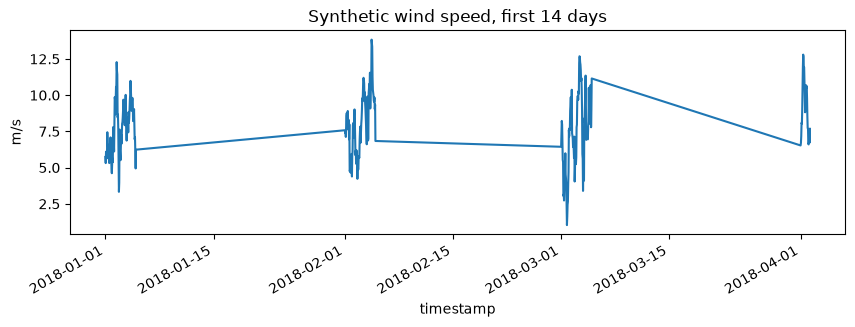

In [4]:
raw['wind_speed'].iloc[:24*14].plot(figsize=(10,3), title='Synthetic wind speed, first 14 days'); plt.ylabel('m/s'); plt.show()

## 2. Features, windows and turbulence proxies φ(t), Iu(t), ∇²v(t)

In [5]:
df = add_features(raw); X, y = make_windows(df, lookback=24); wi = list(df.columns).index('wind_speed')
phi, iu, lap = turbulence_proxies(X[:, :, wi]); tr, va, te = chrono_split(len(X))
sc = Scaler().fit(X[tr]); Xs = sc.transform(X).astype('float32'); phin = ((phi-phi[tr].mean(0))/(phi[tr].std(0)+1e-6)).astype('float32')
last = X[:, -1, wi]                     # last reading = persistence forecast
d = y - last                            # target: change from the last reading
ym, ys = d[tr].mean(), d[tr].std(); yn = ((d-ym)/ys).astype('float32')
pack = lambda s: (Xs[s], phin[s], iu[s], lap[s], yn[s])

/tmp/ipykernel_203664/388953818.py:55: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  h, doy = d.index.hour, d.index.dayofyear


## 3. Train briefly (MSE + 0.1·regime cross-entropy + gate sparsity penalty)

In [6]:
m = run(WuWeiDL(X.shape[2], phi.shape[1], 24), (pack(tr), pack(va)), epochs=EPOCHS); m.eval()
with torch.no_grad(): pred = m(*[torch.tensor(v) for v in pack(te)[:4]]).numpy()*ys + ym + last[te]; G = m.cache['G'].mean(1).numpy()
print('WuWeiDL    ', regression_metrics(y[te], pred))
print('persistence', regression_metrics(y[te], X[te][:, -1, wi]))

WuWeiDL     {'MAE': 0.7321916421254476, 'RMSE': 0.9677166198642896, 'MAPE_%': 9.593182712873, 'R2': 0.8340747493451737}
persistence {'MAE': 0.7786463048723009, 'RMSE': 1.0788346983033934, 'MAPE_%': 10.084407356304313, 'R2': 0.7937823207879058}


### Result in plain words
- **1 h ahead:** model RMSE 0.968 m/s vs persistence 1.079 m/s (R² 0.834 vs 0.794). The model beats persistence here.

These numbers come from about a minute of training on synthetic data. They show that the code works and learns something useful beyond "next hour = this hour"; they are not the paper's results.

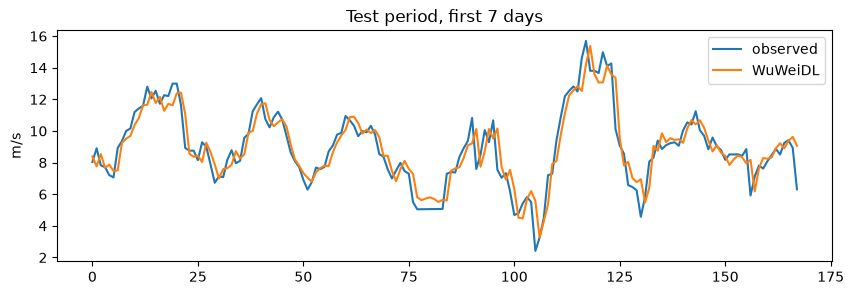

In [7]:
plt.figure(figsize=(10,3)); plt.plot(y[te][:168], label='observed'); plt.plot(pred[:168], label='WuWeiDL'); plt.legend(); plt.ylabel('m/s'); plt.title('Test period, first 7 days'); plt.show()

## 4. Does the gate close in turbulence? (wu wei behavior)

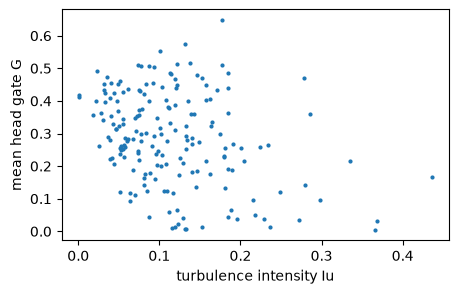

In [8]:
plt.figure(figsize=(5,3)); plt.scatter(iu[te], G, s=4); plt.xlabel('turbulence intensity Iu'); plt.ylabel('mean head gate G'); plt.show()